# Coordination behind farms, relaunches and repeat winners

Notebook 02 showed *what* gets replicated and which copies graduate. This notebook uses the
bonding-curve trades to look at *how*: what happens in a token's first seconds, who buys, whether
the creator sells, and which wallets are likely run by the **same actor**.

**Trade features** (`crypto_analysis.trade_features`, one pass over ~600M trades, day by day):

- **dev buy**: the creator's buy inside the create transaction;
- **bundle**: buys by *other* wallets in the creation slot itself. Landing in the same ~400 ms slot
  as the create in practice means the buys were submitted together with it (a Jito bundle);
- **snipers**: other wallets buying in the next 3 slots (~1.2 s);
- **creator sells**: whether and when the creator wallet sold;
- **buyers (24 h)**: distinct buying wallets in the first 24 h (summed per day file, so a wallet
  buying on both sides of midnight counts twice, a small overcount);
- **direct-invocation share**: the crawler's `is_bot` proxy (Marino et al., 2026). It is *not* a bot
  census.

**Entities** (`crypto_analysis.entities`). Wallets are linked when:

1. they **co-sign a transaction**: every wallet whose trade a transaction carries must sign it, so
   they share control. This is the account-model analogue of the multi-input heuristic
   (Meiklejohn et al., 2013);
2. as creators, they **use the same bundle wallets**: co-action similarity following Pacheco et al.
   (2021). Each creator is a TF-IDF vector of the wallets buying in its creation slots (plus
   itself), and creators with cosine ≥ τ sharing ≥ 2 such wallets are linked.

Entities are connected components of those links. There is no ground truth, so the entities are
validated against something the trades never saw (image reuse, section 5) and reported at several
thresholds. Funding links (who sent SOL to whom) would be the other standard signal, but they are
not in the datalake.

The outcome and time window follow notebook 02: graduation within 24 h, last two launch days dropped.

## Setup

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import networkx as nx
import numpy as np
import pandas as pd

from crypto_analysis.datalake import build_token_flags, connect
from crypto_analysis.entities import resolve_entities
from crypto_analysis.gallery import names_for, show_grid
from crypto_analysis.plotting import (
    COLORS,
    FIG_4x3,
    FIG_6x4,
    GOLD,
    GOLD_CMAP,
    RED_RAMP,
    ROLE_COLORS,
    ccdf,
    count_label,
    dumbbell,
    forest,
    forest_by_row,
    format_date_axis,
    log_ticks,
    pct_label,
    percent_axis,
    radial_clock,
    raincloud,
    rate_series,
    save_figure,
    set_latex_style,
    tex_escape,
    text_color,
    wilson_interval,
)

USE_TEX = set_latex_style()
warnings.filterwarnings("ignore", message="Glyph .* missing from font")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

In [2]:
FIG_DIR = Path("../reports/figures/03_trades_coordination_entities")
SAVE_FIGS = True  # write every figure to FIG_DIR as PDF (for LaTeX) + PNG

# Gephi spreadsheet export of the coordination graphs (section 8)
GEPHI_DIR = Path("../reports/gephi/03_trades_coordination_entities")

# Output of `python -m crypto_analysis.trade_features`
TRADE_DIR = Path("../data/trade_features")

GRAD_WINDOW_HOURS = 24
ENTITY_THRESHOLD = 0.7  # cosine threshold for co-action links (sensitivity in section 4)
SEED = 42
rng = np.random.default_rng(SEED)

con = connect(threads=8, memory_limit="16GB")
build_token_flags(con, grad_window_hours=GRAD_WINDOW_HOURS)


def q(sql):
    return con.execute(sql).df()


BLUE, RED, AQUA = COLORS["blue"], COLORS["red"], COLORS["aqua"]
INK, INK_2, MUTED = COLORS["ink"], COLORS["ink_secondary"], COLORS["muted"]


def save(fig, name):
    if SAVE_FIGS:
        save_figure(fig, FIG_DIR / name)


def rate_table(df, by, outcome="grad_fast", order=None):
    '''Rate of a boolean outcome per group with its 95% (Wilson) interval.'''
    t = df.groupby(by, observed=True)[outcome].agg(k="sum", n="size")
    if order is not None:
        t = t.reindex(order)
    t["rate"] = t.k / t.n
    t["lo"], t["hi"] = wilson_interval(t.k, t.n)
    return t


rate_fmt = {"k": "{:,}", "n": "{:,}", "rate": "{:.2%}", "lo": "{:.2%}", "hi": "{:.2%}"}
PCT_TICKS = ([0.002, 0.005, 0.01, 0.02, 0.05, 0.1], ["0.2", "0.5", "1", "2", "5", "10"])

In [3]:
con.execute(f'''
CREATE OR REPLACE TEMP TABLE trade_feat AS
SELECT mint,
       sum(n_trades)                                         AS n_trades,
       sum(buy_lamports) / 1e9                               AS buy_sol,
       sum(buyers_24h)                                       AS buyers_24h,
       sum(direct_buys) / nullif(sum(known_depth_buys), 0)   AS direct_share,
       coalesce(sum(dev_buy_lamports), 0) / 1e9              AS dev_buy_sol,
       coalesce(sum(creator_buy_lamports), 0) / 1e9          AS creator_buy_sol,
       coalesce(sum(creator_sell_lamports), 0) / 1e9         AS creator_sell_sol,
       min(creator_first_sell)                               AS creator_first_sell,
       coalesce(sum(bundle_wallets), 0)                      AS bundle_wallets,
       coalesce(sum(bundle_lamports), 0) / 1e9               AS bundle_sol,
       coalesce(sum(sniper_wallets), 0)                      AS sniper_wallets
FROM read_parquet('{TRADE_DIR}/token_day/*.parquet')
GROUP BY 1
''')

# One row per token launched in fully observed days, with its replication role and trade features
con.execute('''
CREATE OR REPLACE TEMP TABLE tok AS
WITH creator_size AS (SELECT coin_creator, count(*) AS creator_tokens FROM token_flags GROUP BY 1),
     first_creator AS (SELECT sha256, arg_min(coin_creator, created_at) AS first_creator
                       FROM token_flags GROUP BY 1),
     image_grads AS (SELECT sha256, sum(graduated::INT) AS image_graduations FROM token_flags GROUP BY 1)
SELECT f.mint, f.sha256, f.day, f.created_at, f.coin_creator, f.role, f.graduated, f.grad_fast,
       f.is_copy, f.copies_graduate, f.n_tokens,
       c.creator_tokens, fc.first_creator, ig.image_graduations,
       coalesce(t.n_trades, 0) AS n_trades, coalesce(t.buy_sol, 0) AS buy_sol,
       coalesce(t.buyers_24h, 0) AS buyers_24h, t.direct_share,
       coalesce(t.dev_buy_sol, 0) AS dev_buy_sol,
       coalesce(t.creator_sell_sol, 0) - coalesce(t.creator_buy_sol, 0) AS creator_net_sol,
       t.creator_first_sell - f.created_at AS secs_to_creator_sell,
       coalesce(t.bundle_wallets, 0) AS bundle_wallets, coalesce(t.bundle_sol, 0) AS bundle_sol,
       coalesce(t.sniper_wallets, 0) AS sniper_wallets
FROM token_flags f
JOIN creator_size c USING (coin_creator)
JOIN first_creator fc USING (sha256)
JOIN image_grads ig USING (sha256)
LEFT JOIN trade_feat t USING (mint)
WHERE f.day < (SELECT max(day) - 1 FROM token_flags)
''')
tok = q("SELECT * FROM tok")
tok["bundled"] = tok.bundle_wallets > 0
tok["sniped"] = tok.sniper_wallets > 0
tok["creator_sold_1h"] = tok.secs_to_creator_sell.le(3600).fillna(False)
tok["creator_size"] = pd.cut(tok.creator_tokens, [0, 1, 10, 100, np.inf],
                             labels=["1", "2-10", "11-100", "> 100"])
print(f"{len(tok):,} tokens; {(tok.n_trades > 0).mean():.1%} have bonding-curve trades")

5,114,901 tokens; 97.9% have bonding-curve trades


## 1. What a launch looks like

Shares of tokens with each launch pattern, and the graduation rate (24 h) of each group.

In [4]:
patterns = pd.DataFrame({
    "share of tokens": [(tok.dev_buy_sol > 0).mean(), tok.bundled.mean(), tok.sniped.mean(),
                        tok.creator_sold_1h.mean()],
    "graduation if yes": [tok.loc[tok.dev_buy_sol > 0, "grad_fast"].mean(),
                          tok.loc[tok.bundled, "grad_fast"].mean(),
                          tok.loc[tok.sniped, "grad_fast"].mean(),
                          tok.loc[tok.creator_sold_1h, "grad_fast"].mean()],
    "graduation if no": [tok.loc[tok.dev_buy_sol == 0, "grad_fast"].mean(),
                         tok.loc[~tok.bundled, "grad_fast"].mean(),
                         tok.loc[~tok.sniped, "grad_fast"].mean(),
                         tok.loc[~tok.creator_sold_1h, "grad_fast"].mean()],
}, index=["dev buy in the create tx", "bundle (other wallets, creation slot)",
          "snipers (next 3 slots)", "creator sold within 1 h"])
display(patterns.style.format("{:.2%}"))
print(f"Median bundle size when bundled: {tok.loc[tok.bundled, 'bundle_wallets'].median():.0f} wallets, "
      f"{tok.loc[tok.bundled, 'bundle_sol'].median():.2f} SOL")

,share of tokens,graduation if yes,graduation if no
dev buy in the create tx,95.23%,0.92%,0.85%
"bundle (other wallets, creation slot)",39.27%,1.71%,0.41%
snipers (next 3 slots),43.62%,1.41%,0.54%
creator sold within 1 h,81.34%,0.61%,2.26%


Median bundle size when bundled: 2 wallets, 1.74 SOL


,k,n,rate,lo,hi
bundle_bucket,,,,,
0,"12,696","3,106,179",0.41%,0.40%,0.42%
1,"5,355","733,590",0.73%,0.71%,0.75%
2-3,"12,326","707,511",1.74%,1.71%,1.77%
4-6,"10,664","407,197",2.62%,2.57%,2.67%
7+,"6,042","160,424",3.77%,3.67%,3.86%


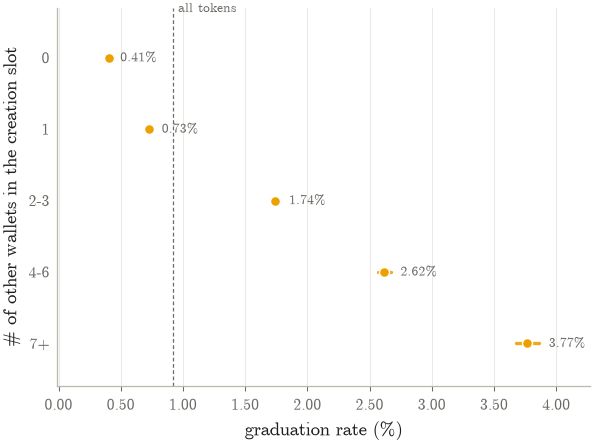

In [5]:
BUNDLE = ["0", "1", "2-3", "4-6", "7+"]
tok["bundle_bucket"] = pd.cut(tok.bundle_wallets, [-1, 0, 1, 3, 6, np.inf], labels=BUNDLE)
bundle_t = rate_table(tok, "bundle_bucket", order=BUNDLE)
display(bundle_t.style.format(rate_fmt))

fig, ax = plt.subplots(figsize=FIG_4x3)
forest(ax, BUNDLE, [rate_series("graduation", GOLD, bundle_t.k, bundle_t.n)],
       ref=tok.grad_fast.mean(), ref_label="all tokens")
ax.set_xlabel(pct_label("graduation rate"))
ax.set_ylabel(count_label("other wallets in the creation slot"))
save(fig, "graduation_by_bundle")

Bundle size and creator size **together**: is the bundle effect the same for one-off creators and
for farms? One row per bundle size, one dot per creator size (lighter red = fewer tokens per wallet),
with 95% intervals; combinations with fewer than 500 tokens are omitted.

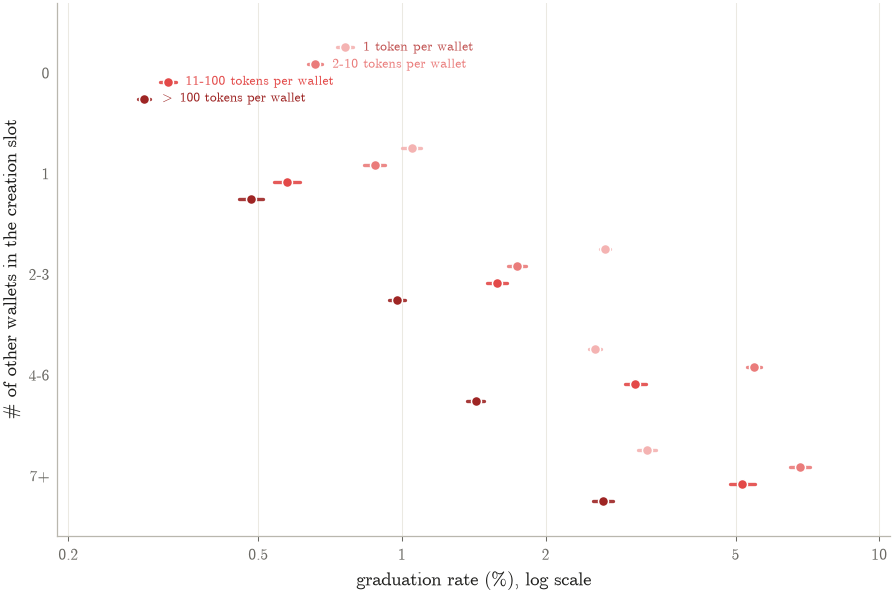

In [6]:
SIZES = ["1", "2-10", "11-100", "> 100"]
cells = tok.groupby(["bundle_bucket", "creator_size"], observed=True).grad_fast.agg(k="sum", n="size")
series = []
for size, color in zip(SIZES, RED_RAMP):
    t = cells.xs(size, level="creator_size").reindex(BUNDLE)
    t.loc[t.n < 500, ["k", "n"]] = np.nan  # too few tokens for a stable estimate
    series.append(rate_series(f"{size} token" + ("" if size == "1" else "s") + " per wallet", color, t.k, t.n))

fig, ax = plt.subplots(figsize=FIG_6x4)
forest(ax, BUNDLE, series, log=True, spacing=0.17)
log_ticks(ax, "x", *PCT_TICKS)
ax.set_xlabel(pct_label("graduation rate") + ", log scale")
ax.set_ylabel(count_label("other wallets in the creation slot"))
save(fig, "graduation_bundle_x_creator_size")

## 2. Farms, relaunches and repeat winners through their trades

The same launch patterns, by replication role (notebook 02) and by how many tokens the creator
wallet launched. "Creator net" is what the creator *wallet* took out of the curve on that token
(sells minus buys, in SOL); other wallets of the same actor are not included.

In [7]:
ROLES = ["original", "self-relaunch", "copy (other creator)", "copy of a graduate"]
SIZES = ["1", "2-10", "11-100", "> 100"]


def profile(df, by, order):
    g = df.groupby(by, observed=True)
    t = pd.DataFrame({
        "tokens": g.size(),
        "bundled": g.bundled.mean(),
        "sniped": g.sniped.mean(),
        "creator sold ≤ 1 h": g.creator_sold_1h.mean(),
        "median dev buy (SOL)": g.dev_buy_sol.median(),
        "creator came out ahead": g.creator_net_sol.apply(lambda v: (v > 0).mean()),
        "mean creator net (SOL)": g.creator_net_sol.mean(),
        "median buyers 24 h": g.buyers_24h.median(),
        "direct-invocation share": g.direct_share.mean(),
        "graduation (24 h)": g.grad_fast.mean(),
    }).reindex(order)
    return t


prof_fmt = {"tokens": "{:,}", "bundled": "{:.1%}", "sniped": "{:.1%}", "creator sold ≤ 1 h": "{:.1%}",
            "median dev buy (SOL)": "{:.2f}", "creator came out ahead": "{:.1%}",
            "mean creator net (SOL)": "{:.2f}",
            "median buyers 24 h": "{:.0f}", "direct-invocation share": "{:.1%}",
            "graduation (24 h)": "{:.2%}"}
role_prof = profile(tok, "role", ROLES)
size_prof = profile(tok, "creator_size", SIZES)
display(role_prof.style.format(prof_fmt))
display(size_prof.style.format(prof_fmt))

,tokens,bundled,sniped,creator sold ≤ 1 h,median dev buy (SOL),creator came out ahead,mean creator net (SOL),median buyers 24 h,direct-invocation share,graduation (24 h)
role,,,,,,,,,,
original,"2,726,093",44.6%,45.9%,82.2%,0.60,49.7%,0.32,5,62.5%,1.19%
self-relaunch,"881,612",19.8%,37.4%,82.6%,0.15,32.8%,0.13,3,51.1%,0.32%
copy (other creator),"1,283,196",43.3%,43.6%,79.2%,0.50,46.4%,0.34,4,68.0%,0.62%
copy of a graduate,"224,000",27.6%,40.1%,78.3%,0.20,34.0%,0.36,3,59.5%,1.78%


,tokens,bundled,sniped,creator sold ≤ 1 h,median dev buy (SOL),creator came out ahead,mean creator net (SOL),median buyers 24 h,direct-invocation share,graduation (24 h)
creator_size,,,,,,,,,,
1,"965,079",65.4%,63.5%,80.0%,0.98,64.7%,0.49,10,67.3%,1.71%
2-10,"862,396",41.5%,42.5%,76.8%,0.28,43.3%,0.18,4,65.0%,1.34%
11-100,"1,191,102",27.1%,33.4%,76.8%,0.12,34.2%,0.20,3,63.3%,0.65%
> 100,"2,096,324",33.2%,40.8%,86.4%,0.68,43.5%,0.30,4,57.0%,0.54%


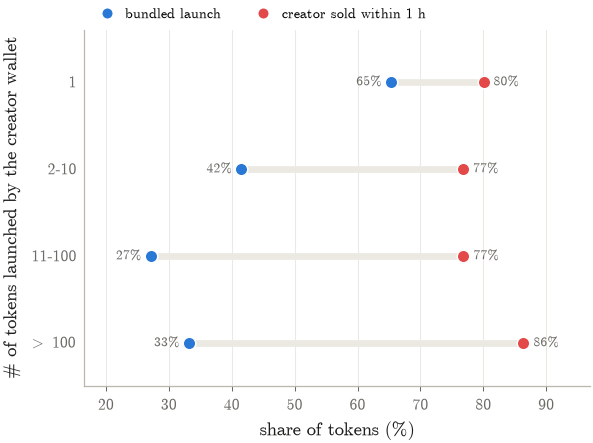

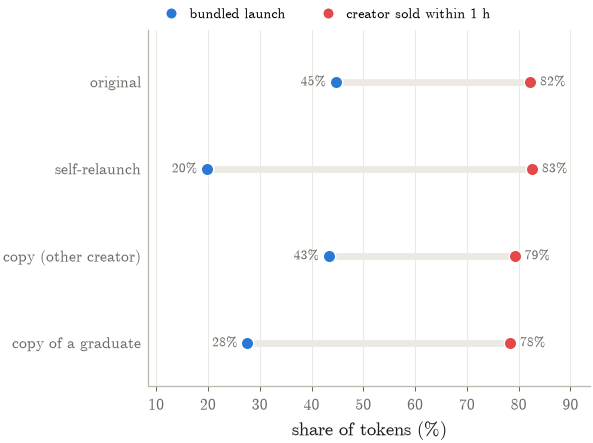

In [8]:
fig, ax = plt.subplots(figsize=FIG_4x3)
dumbbell(ax, SIZES, size_prof.bundled.to_numpy(), size_prof["creator sold ≤ 1 h"].to_numpy(),
         left_label="bundled launch", right_label="creator sold within 1 h", left_color=BLUE,
         right_color=RED, value_fmt="{:.0%}")
ax.set_xlabel(pct_label("share of tokens"))
ax.set_ylabel(count_label("tokens launched by the creator wallet"))
save(fig, "farm_launch_patterns")

fig, ax = plt.subplots(figsize=FIG_4x3)
dumbbell(ax, ROLES, role_prof.bundled.to_numpy(), role_prof["creator sold ≤ 1 h"].to_numpy(),
         left_label="bundled launch", right_label="creator sold within 1 h", left_color=BLUE,
         right_color=RED, value_fmt="{:.0%}")
ax.set_xlabel(pct_label("share of tokens"))
save(fig, "role_launch_patterns")

**When do they launch?** Share of each group's launches by hour of day (UTC), as 24-hour clocks.
Humans follow a daily rhythm; farms launch more evenly around the clock.

one-off creators (1 token): busiest hour 2.4x the quietest
farms (> 100 tokens per wallet): busiest hour 1.9x the quietest


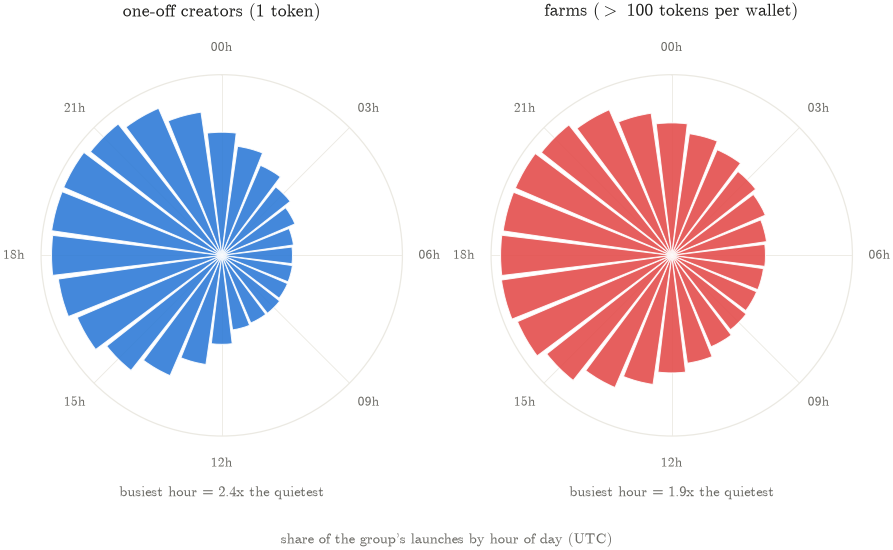

In [9]:
when = pd.to_datetime(tok.created_at, unit="s", utc=True)
tok["hour"] = when.dt.hour
panels = [("one-off creators (1 token)", tok.creator_size == "1", BLUE),
          ("farms (> 100 tokens per wallet)", tok.creator_size == "> 100", RED)]

fig = plt.figure(figsize=FIG_6x4)
for j, (title, mask, color) in enumerate(panels):
    hourly = tok.loc[mask, "hour"].value_counts(normalize=True).reindex(range(24), fill_value=0)
    ax = fig.add_subplot(1, 2, j + 1, projection="polar")
    radial_clock(ax, hourly.to_numpy(), color=color, title=title)
    ax.set_xlabel(tex_escape(f"busiest hour = {hourly.max() / hourly.min():.1f}x the quietest"), fontsize=7,
                  color=INK_2, labelpad=8)
    print(f"{title}: busiest hour {hourly.max() / hourly.min():.1f}x the quietest")
fig.text(0.5, 0.02, "share of the group's launches by hour of day (UTC)", ha="center", fontsize=7, color=INK_2)
save(fig, "launch_clock")

**Farm cadence.** Every launch of the 25 most prolific creator wallets over time (red ticks); gold
dots are launches that graduated within 24 h.

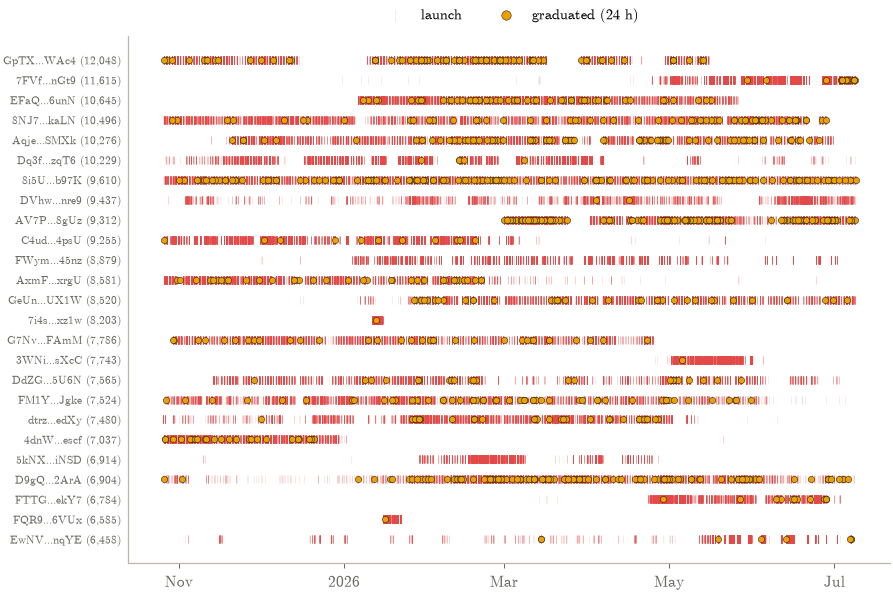

In [10]:
top_farms = tok.coin_creator.value_counts().head(25)
farm = tok[tok.coin_creator.isin(top_farms.index)].copy()
farm["row"] = farm.coin_creator.map(pd.Series(np.arange(len(top_farms)), index=top_farms.index))
farm["when"] = pd.to_datetime(farm.created_at, unit="s")

fig, ax = plt.subplots(figsize=FIG_6x4)
ax.scatter(farm.when, farm.row, marker="|", s=14, linewidths=0.3, color=RED, alpha=0.18, label="launch")
g = farm[farm.grad_fast]
ax.scatter(g.when, g.row, s=9, color=GOLD, edgecolors=INK, linewidths=0.25, zorder=3, label="graduated (24 h)")
ax.set_yticks(range(len(top_farms)),
              [f"{w[:4]}...{w[-4:]} ({n:,})" for w, n in zip(top_farms.index, top_farms.to_numpy())],
              fontsize=5.5)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
format_date_axis(ax)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=7, markerscale=1.5)
save(fig, "farm_cadence")

### How do graduates get there?

Among **graduated** tokens: are graduations of repeat-winner images (images that graduated more than
once) bought by a broad crowd, or carried by bundles?

,tokens,bundled,sniped,creator sold ≤ 1 h,median dev buy (SOL),creator came out ahead,mean creator net (SOL),median buyers 24 h,direct-invocation share
image,,,,,,,,,
single-graduation image,"44,620",70.3%,66.9%,54.8%,1.47,46.1%,-0.92,235,35.9%
repeat-winner image,"8,070",56.6%,54.9%,47.1%,1.19,31.8%,-0.56,20,41.5%


single-graduation image: 10.5% of graduations with at most 5 buyers, 24.7% with at most 20
repeat-winner image: 24.0% of graduations with at most 5 buyers, 50.6% with at most 20


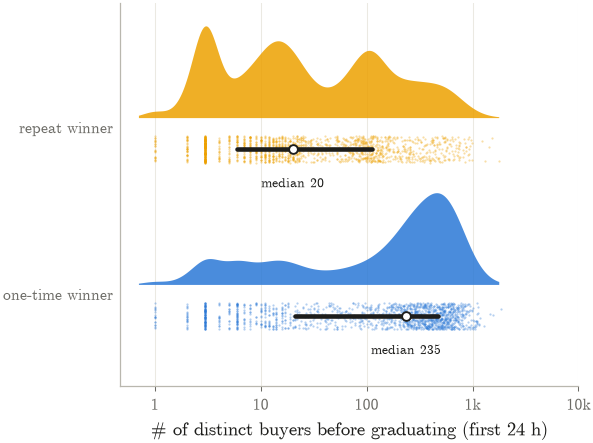

In [11]:
grads = tok[tok.graduated].copy()
grads["image"] = np.where(grads.image_graduations > 1, "repeat-winner image", "single-graduation image")
GROUPS = ["single-graduation image", "repeat-winner image"]
grad_prof = profile(grads, "image", GROUPS).drop(columns="graduation (24 h)")
display(grad_prof.style.format(prof_fmt))

for name in GROUPS:
    v = grads.loc[grads.image == name, "buyers_24h"]
    print(f"{name}: {(v <= 5).mean():.1%} of graduations with at most 5 buyers, "
          f"{(v <= 20).mean():.1%} with at most 20")

fig, ax = plt.subplots(figsize=FIG_4x3)
raincloud(ax, [("one-time winner", grads.loc[grads.image == GROUPS[0], "buyers_24h"].clip(lower=1), BLUE),
               ("repeat winner", grads.loc[grads.image == GROUPS[1], "buyers_24h"].clip(lower=1), GOLD)],
          log10=True, summary_fmt="median {:,.0f}")
log_ticks(ax, "x", [0, 1, 2, 3, 4], ["1", "10", "100", "1k", "10k"])
ax.set_xlabel(count_label("distinct buyers before graduating (first 24 h)"))
save(fig, "graduate_buyers")

**Crowd vs. insiders.** For every graduated token: distinct buyers in the first 24 h against the
SOL the launch side put in (creator's dev buy + bundle). Hexagon colour is the number of graduations
(log scale). Repeat-winner graduations sit lower on the crowd axis.

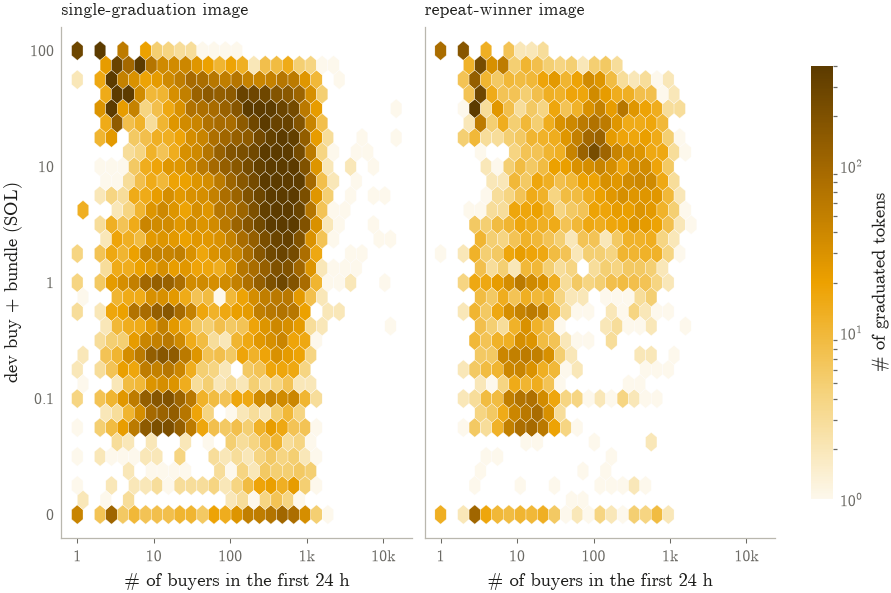

In [12]:
grads["insider_sol"] = grads.dev_buy_sol + grads.bundle_sol
x_all = np.log10(grads.buyers_24h.clip(lower=1))
y_all = np.log10(grads.insider_sol + 0.01)
extent = (0, x_all.max(), y_all.min(), y_all.max())

fig, axes = plt.subplots(1, 2, figsize=FIG_6x4, sharex=True, sharey=True)
for ax, name in zip(axes, GROUPS):
    m = grads.image == name
    hb = ax.hexbin(x_all[m], y_all[m], gridsize=28, extent=extent, mincnt=1, cmap=GOLD_CMAP,
                   norm=LogNorm(vmin=1, vmax=400), linewidths=0.15, edgecolors="white")
    ax.set_title(tex_escape(name), fontsize=8.5)
    ax.set_xticks([0, 1, 2, 3, 4], ["1", "10", "100", "1k", "10k"])
    ax.set_xlabel(count_label("buyers in the first 24 h"))
    ax.grid(False)
axes[0].set_yticks([-2, -1, 0, 1, 2], ["0", "0.1", "1", "10", "100"])
axes[0].set_ylabel("dev buy + bundle (SOL)")
cbar = fig.colorbar(hb, ax=axes, shrink=0.85)
cbar.set_label(count_label("graduated tokens"))
cbar.outline.set_visible(False)
save(fig, "graduates_crowd_vs_insiders")

## 3. Wallet evidence

How much evidence is there to link wallets? Bundle buys (creation slot) and co-signed transactions,
over the whole period.

In [13]:
bundle = pd.concat([pd.read_parquet(p, columns=["mint", "coin_creator", "trader", "slot_offset"])
                    for p in sorted((TRADE_DIR / "bundle").glob("*.parquet"))], ignore_index=True)
bundle = bundle[bundle.slot_offset == 0].drop(columns="slot_offset").drop_duplicates()
cosign = pd.concat([pd.read_parquet(p) for p in sorted((TRADE_DIR / "cosign").glob("*.parquet"))],
                   ignore_index=True)
per_wallet = bundle.groupby("trader").coin_creator.nunique()
print(f"Bundle buys: {len(bundle):,} (token, wallet) pairs by {bundle.trader.nunique():,} wallets "
      f"for {bundle.coin_creator.nunique():,} creators")
print(f"Co-signed transactions: {cosign.signature.nunique():,}, {cosign.trader.nunique():,} wallets")
display(pd.cut(per_wallet, [0, 1, 2, 5, 20, 50, np.inf],
               labels=["1", "2", "3-5", "6-20", "21-50", "> 50"]).value_counts(sort=False)
        .to_frame("bundle wallets by number of creators served").T)

Bundle buys: 7,648,991 (token, wallet) pairs by 511,939 wallets for 878,896 creators
Co-signed transactions: 10,722, 8,649 wallets


coin_creator,1,2,3-5,6-20,21-50,> 50
bundle wallets by number of creators served,374850,62556,44178,20529,4689,5137


## 4. Entities: sensitivity to the threshold

Links and entities at several cosine thresholds (always requiring ≥ 2 shared bundle wallets).
Lower thresholds link more creators but risk merging unrelated actors.

,creators,coaction_links,cosign_links,dropped_hub_wallets,entities_with_2plus_creators,largest entity (creators),creators in multi-wallet entities
threshold,,,,,,,
0.500000,"878,896","282,511","6,778","5,137","14,866",348,"73,707"
0.600000,"878,896","148,098","6,778","5,137","12,185",305,"50,686"
0.700000,"878,896","47,343","6,778","5,137","6,487",96,"22,284"
0.800000,"878,896","4,819","6,778","5,137","2,331",44,"6,170"
0.900000,"878,896","2,254","6,778","5,137","1,381",24,"3,242"


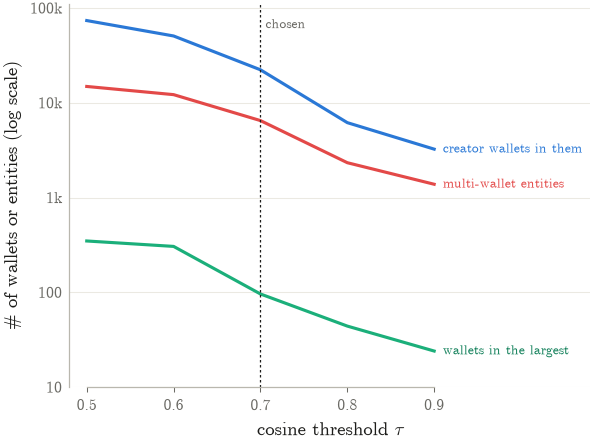

In [14]:
sens = []
results = {}
for th in (0.5, 0.6, 0.7, 0.8, 0.9):
    creator_entity, wallet_entity, edges, info = resolve_entities(bundle, cosign, threshold=th)
    sizes = creator_entity.value_counts()
    sens.append({"threshold": th, **info, "largest entity (creators)": int(sizes.max()),
                 "creators in multi-wallet entities": int(sizes[sizes > 1].sum())})
    results[th] = (creator_entity, wallet_entity, edges)
sens = pd.DataFrame(sens).set_index("threshold")
display(sens.style.format("{:,}"))

fig, ax = plt.subplots(figsize=FIG_4x3)
for col, label, color in [("creators in multi-wallet entities", "creator wallets in them", BLUE),
                          ("entities_with_2plus_creators", "multi-wallet entities", RED),
                          ("largest entity (creators)", "wallets in the largest", AQUA)]:
    ax.plot(sens.index, sens[col], color=color, lw=1.5)
    ax.text(sens.index[-1] + 0.01, sens[col].iloc[-1], tex_escape(label), fontsize=6.5, va="center",
            color=text_color(color))
ax.axvline(ENTITY_THRESHOLD, color=INK, lw=0.6, ls=(0, (2, 2)))
ax.text(ENTITY_THRESHOLD, ax.get_ylim()[1], " chosen", fontsize=6.5, color=INK_2, va="top")
ax.set_yscale("log")
log_ticks(ax, "y", [10, 100, 1_000, 10_000, 100_000])
ax.set_xlim(0.48, 1.08)
ax.spines["bottom"].set_bounds(0.5, 0.9)
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9])
ax.set_xlabel(r"cosine threshold $\tau$")
ax.set_ylabel(count_label("wallets or entities") + " (log scale)")
save(fig, "entity_threshold_sensitivity")

creator_entity, wallet_entity, edges = results[ENTITY_THRESHOLD]


def entity_of(creators):
    '''Entity label for creator wallets; creators never linked are their own entity.'''
    e = creator_entity.reindex(creators).to_numpy()
    linked = ~pd.isna(e)
    labels = np.array([f"w:{c}" for c in creators], dtype=object)
    labels[linked] = [f"e:{int(v)}" for v in e[linked]]
    return labels


tok["entity"] = entity_of(tok.coin_creator.to_numpy())
tok["first_entity"] = entity_of(tok.first_creator.to_numpy())

Multi-wallet entities: 5,781, with 19,635 creator wallets and 240,362 tokens (4.7% of all tokens)


,count,mean,std,min,25%,50%,75%,max
creators,5781.0,3.4,3.5,2.0,2.0,2.0,3.0,96.0
tokens,5781.0,41.6,223.6,2.0,2.0,3.0,8.0,4582.0
graduations,5781.0,0.3,2.2,0.0,0.0,0.0,0.0,80.0


Multi-wallet entities where every creator wallet launched exactly one token: 61.7% (wallet rotation)


Top 0.1% creator wallets launch 27.9% of tokens; top 0.1% entities launch 28.6%


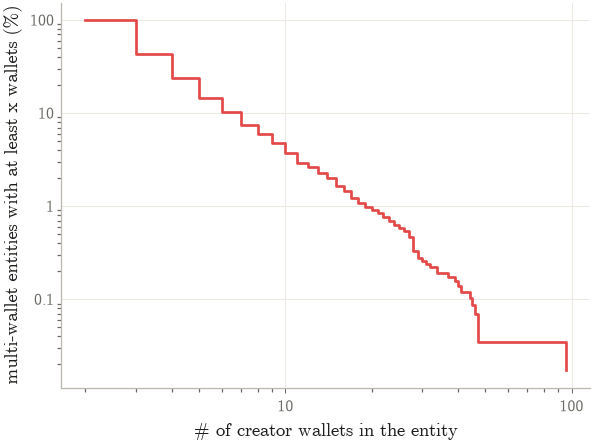

In [15]:
ent = tok.groupby("entity").agg(creators=("coin_creator", "nunique"), tokens=("mint", "size"),
                                graduations=("grad_fast", "sum"))
multi = ent[ent.creators > 1]
print(f"Multi-wallet entities: {len(multi):,}, with {multi.creators.sum():,} creator wallets "
      f"and {multi.tokens.sum():,} tokens ({multi.tokens.sum() / len(tok):.1%} of all tokens)")
display(multi.describe().round(1).T)
print(f"Multi-wallet entities where every creator wallet launched exactly one token: "
      f"{(multi.tokens == multi.creators).mean():.1%} (wallet rotation)")

top_wallets = tok.coin_creator.value_counts()
top_entities = ent.tokens.sort_values(ascending=False)
k_w, k_e = max(1, len(top_wallets) // 1000), max(1, len(top_entities) // 1000)
print(f"Top 0.1% creator wallets launch {top_wallets.head(k_w).sum() / len(tok):.1%} of tokens; "
      f"top 0.1% entities launch {top_entities.head(k_e).sum() / len(tok):.1%}")

fig, ax = plt.subplots(figsize=FIG_4x3)
ccdf(ax, multi.creators, color=RED)
ax.set_xlabel(count_label("creator wallets in the entity"))
ax.set_ylabel(pct_label("multi-wallet entities with at least x wallets"))
save(fig, "entity_sizes")

**Concentration.** Lorenz curves of launches: the share of all tokens launched by the most active
x% of actors, counting actors as wallets or as entities. The closer to the top-left corner, the
more concentrated. Gini coefficients are in the legend.

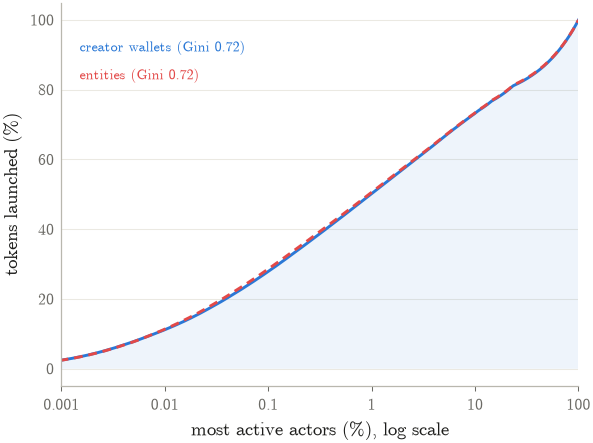

In [16]:
def lorenz(counts):
    c = np.sort(np.asarray(counts, dtype=float))[::-1]
    return np.r_[0, np.arange(1, len(c) + 1) / len(c)], np.r_[0, np.cumsum(c) / c.sum()]


def gini(counts):
    c = np.sort(np.asarray(counts, dtype=float))
    n = len(c)
    return (2 * np.arange(1, n + 1) - n - 1).dot(c) / (n * c.sum())


fig, ax = plt.subplots(figsize=FIG_4x3)
for label, counts, color, ls in [("creator wallets", tok.coin_creator.value_counts(), BLUE, "-"),
                                 ("entities", ent.tokens, RED, (0, (3, 2)))]:
    x, y = lorenz(counts)
    ax.plot(x, y, color=color, lw=1.4, ls=ls)
    ax.text(1.5e-5, 0.92 if color == BLUE else 0.84, tex_escape(f"{label} (Gini {gini(counts):.2f})"),
            fontsize=6.8, color=color, va="center")
ax.fill_between(*lorenz(tok.coin_creator.value_counts()), color=BLUE, alpha=0.08, lw=0)
ax.set_xscale("log")
ax.set_xlim(1e-5, 1)
log_ticks(ax, "x", [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1], ["0.001", "0.01", "0.1", "1", "10", "100"])
percent_axis(ax)
ax.set_xlabel(pct_label("most active actors") + ", log scale")
ax.set_ylabel(pct_label("tokens launched"))
save(fig, "launch_concentration_lorenz")

**What an entity looks like.** The six largest multi-wallet entities: creator wallets (blue, size
by tokens launched; gold if the wallet graduated a token) and the bundle wallets buying in their
creation slots (grey). Grey edges join a creator to its bundle wallets; red edges are co-action links
between creators. Layout: ForceAtlas2.

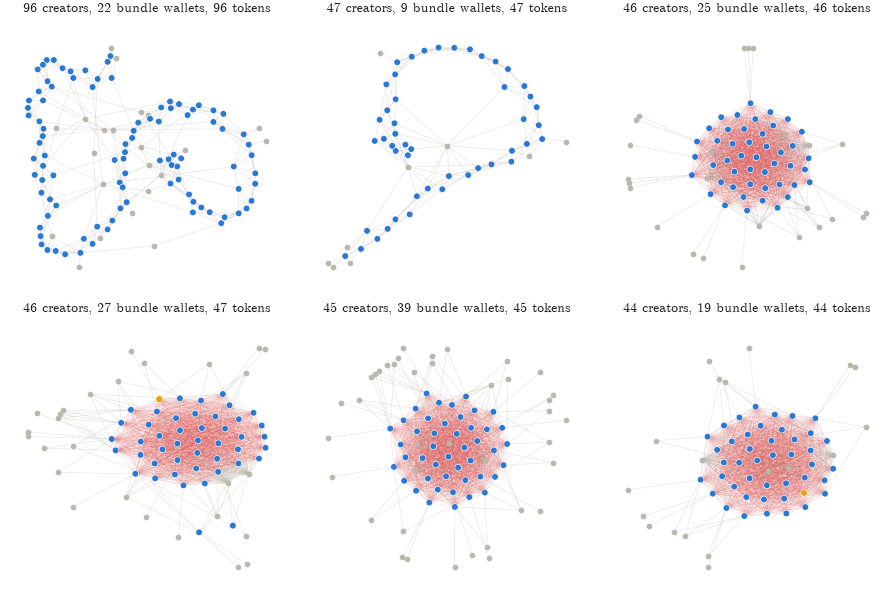

In [17]:
largest = multi.sort_values("creators", ascending=False).head(6).index
graduated_creators = set(tok.loc[tok.graduated, "coin_creator"])
fig, axes = plt.subplots(2, 3, figsize=FIG_6x4)
creator_tokens = tok.coin_creator.value_counts()
for ax, e in zip(axes.ravel(), largest):
    creators_e = tok.loc[tok.entity == e, "coin_creator"].unique()
    G = nx.Graph()
    b = bundle[bundle.coin_creator.isin(creators_e)]
    G.add_nodes_from(creators_e, kind="creator")
    G.add_nodes_from([w for w in b.trader.unique() if w not in G], kind="wallet")
    G.add_edges_from(zip(b.coin_creator, b.trader), kind="bundle")
    co = edges[(edges.kind == "coaction") & edges.source.isin(creators_e) & edges.target.isin(creators_e)]
    G.add_edges_from(zip(co.source, co.target), kind="coaction")
    pos = nx.forceatlas2_layout(G, max_iter=200, scaling_ratio=2.0, gravity=2.0, seed=SEED)
    kinds = nx.get_edge_attributes(G, "kind")
    nx.draw_networkx_edges(G, pos, ax=ax, width=0.3, alpha=0.35, edge_color=MUTED,
                           edgelist=[uv for uv in G.edges if kinds[uv] == "bundle"])
    nx.draw_networkx_edges(G, pos, ax=ax, width=0.25, alpha=0.18, edge_color=RED,
                           edgelist=[uv for uv in G.edges if kinds[uv] == "coaction"])
    wallets = [n for n, d in G.nodes(data=True) if d["kind"] == "wallet"]
    nx.draw_networkx_nodes(G, pos, nodelist=wallets, ax=ax, node_size=3, node_color=MUTED)
    colors = [GOLD if c in graduated_creators else BLUE for c in creators_e]
    sizes = [6 + 4 * np.sqrt(creator_tokens.get(c, 1)) for c in creators_e]
    nx.draw_networkx_nodes(G, pos, nodelist=list(creators_e), ax=ax, node_size=sizes, node_color=colors,
                           edgecolors="white", linewidths=0.3)
    ax.set_title(tex_escape(f"{len(creators_e)} creators, {len(wallets)} bundle wallets, "
                            f"{int(ent.loc[e, 'tokens']):,} tokens"), fontsize=6.5, loc="center")
    ax.axis("off")
save(fig, "entity_networks")

**Constellation.** The 40 largest multi-wallet entities at once (ForceAtlas2 layout, as in Gephi):
creator wallets in blue (gold if they graduated a token), each entity's own bundle wallets in grey, and
in red the bundle wallets **shared across entities**, the links that may tie separate entities to one
larger operator or a common bundling service.

Bundle wallets shared by 2+ of these 40 entities: 172


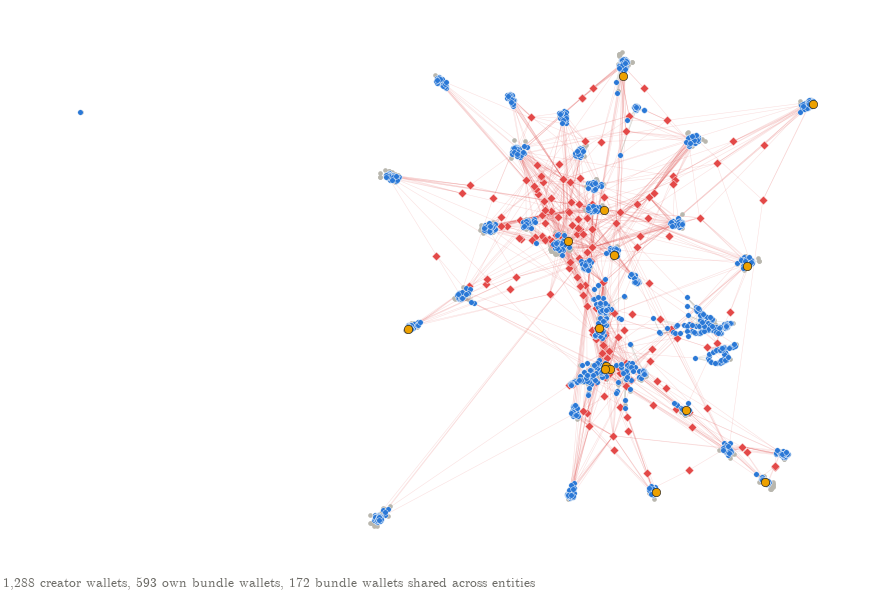

In [18]:
chosen = multi.sort_values("creators", ascending=False).head(40).index
members = tok.loc[tok.entity.isin(chosen), ["coin_creator", "entity"]].drop_duplicates("coin_creator")
member_entity = members.set_index("coin_creator").entity
b = bundle[bundle.coin_creator.isin(member_entity.index)]
entities_per_wallet = b.assign(e=b.coin_creator.map(member_entity)).groupby("trader").e.nunique()

G = nx.Graph()
G.add_nodes_from(member_entity.index, kind="creator")
for w in b.trader.unique():
    if w not in G:
        G.add_node(w, kind="shared" if entities_per_wallet[w] > 1 else "wallet")
G.add_edges_from(zip(b.coin_creator, b.trader))
co = edges[(edges.kind == "coaction") & edges.source.isin(member_entity.index)
           & edges.target.isin(member_entity.index)]
G.add_edges_from(zip(co.source, co.target))
G.remove_nodes_from([n for comp in nx.connected_components(G) if len(comp) < 3 for n in comp])
pos = nx.forceatlas2_layout(G, max_iter=300, scaling_ratio=2.0, gravity=1.5, seed=SEED)

kind = nx.get_node_attributes(G, "kind")
shared_edges = [(u, v) for u, v in G.edges if "shared" in (kind[u], kind[v])]
own_edges = [(u, v) for u, v in G.edges if "shared" not in (kind[u], kind[v])]
fig, ax = plt.subplots(figsize=FIG_6x4)
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=own_edges, width=0.3, alpha=0.35, edge_color=MUTED)
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=shared_edges, width=0.25, alpha=0.18, edge_color=RED)
own = [n for n in G if kind[n] == "wallet"]
shared = [n for n in G if kind[n] == "shared"]
nx.draw_networkx_nodes(G, pos, nodelist=own, ax=ax, node_size=1.5, node_color=MUTED)
nx.draw_networkx_nodes(G, pos, nodelist=shared, ax=ax, node_size=9, node_color=RED, node_shape="D",
                       edgecolors="white", linewidths=0.2)
plain = [c for c in member_entity.index if c in G and c not in graduated_creators]
golden = [c for c in member_entity.index if c in G and c in graduated_creators]
nx.draw_networkx_nodes(G, pos, nodelist=plain, ax=ax, node_size=7, node_color=BLUE, edgecolors="white",
                       linewidths=0.2)
nx.draw_networkx_nodes(G, pos, nodelist=golden, ax=ax, node_size=16, node_color=GOLD, edgecolors=INK,
                       linewidths=0.3)
ax.axis("off")
ax.text(0.0, -0.02, tex_escape(f"{len(member_entity):,} creator wallets, {len(own):,} own bundle wallets, "
                               f"{len(shared):,} bundle wallets shared across entities"),
        transform=ax.transAxes, fontsize=6.5, color=INK_2)
save(fig, "entity_constellation")
print(f"Bundle wallets shared by 2+ of these 40 entities: {len(shared):,}")

## 5. Validation: do linked wallets also share images?

The links come only from trades. If they capture real actors, creator wallets in the same entity
should also **reuse each other's images** far more than chance. Metric: images used by two or more
creator wallets *of the same entity*. Baseline: the same count after shuffling entity labels among
the creators of multi-wallet entities (keeping entity sizes), 20 times.

In [19]:
multi_creators = creator_entity[creator_entity.map(creator_entity.value_counts()) > 1]
img_creators = tok.loc[tok.coin_creator.isin(multi_creators.index), ["sha256", "coin_creator"]].drop_duplicates()


def shared_images(labels):
    e = img_creators.coin_creator.map(labels)
    per = img_creators.assign(e=e.to_numpy()).groupby(["sha256", "e"]).coin_creator.nunique()
    return int((per > 1).sum())


observed = shared_images(multi_creators)
baseline = [shared_images(pd.Series(rng.permutation(multi_creators.to_numpy()), index=multi_creators.index))
            for _ in range(20)]
print(f"Images shared by 2+ wallets of the same entity: {observed:,} observed, "
      f"{np.mean(baseline):,.0f} ± {np.std(baseline):,.0f} under shuffled entities "
      f"({observed / max(np.mean(baseline), 1):.0f}x)")

Images shared by 2+ wallets of the same entity: 5,032 observed, 12 ± 10 under shuffled entities (406x)


## 6. The findings again, at entity level

### 6.1 Hidden self-relaunches

Notebook 02 called a copy a *self-relaunch* only when the **same wallet** relaunched the image.
With entities, a copy by a *different wallet of the same entity* is also a self-relaunch.

In [20]:
same_actor = tok.entity == tok.first_entity
tok["entity_role"] = np.select(
    [~tok.is_copy,
     tok.copies_graduate & same_actor,
     tok.copies_graduate,
     tok.role == "self-relaunch",
     same_actor],
    ["original",
     "copy of a graduate (own entity)",
     "copy of a graduate (outsider)",
     "self-relaunch (same wallet)",
     "self-relaunch (other wallet, same entity)"],
    default="copy (other actor)")
EROLES = ["original", "self-relaunch (same wallet)", "self-relaunch (other wallet, same entity)",
          "copy (other actor)", "copy of a graduate (own entity)", "copy of a graduate (outsider)"]
erole_t = rate_table(tok, "entity_role", order=EROLES)
erole_t["share of tokens"] = erole_t.n / erole_t.n.sum()
display(erole_t.style.format({**rate_fmt, "share of tokens": "{:.1%}"}))
other = tok[tok.role == "copy (other creator)"]
print(f"'Copies by another creator' that are actually the same entity: "
      f"{(other.entity == other.first_entity).mean():.1%}")

,k,n,rate,lo,hi,share of tokens
entity_role,,,,,,
original,"32,392","2,726,093",1.19%,1.18%,1.20%,53.3%
self-relaunch (same wallet),"2,782","881,612",0.32%,0.30%,0.33%,17.2%
"self-relaunch (other wallet, same entity)",44,"6,565",0.67%,0.50%,0.90%,0.1%
copy (other actor),"7,882","1,276,631",0.62%,0.60%,0.63%,25.0%
copy of a graduate (own entity),"1,117","46,194",2.42%,2.28%,2.56%,0.9%
copy of a graduate (outsider),"2,866","177,806",1.61%,1.55%,1.67%,3.5%


'Copies by another creator' that are actually the same entity: 0.5%


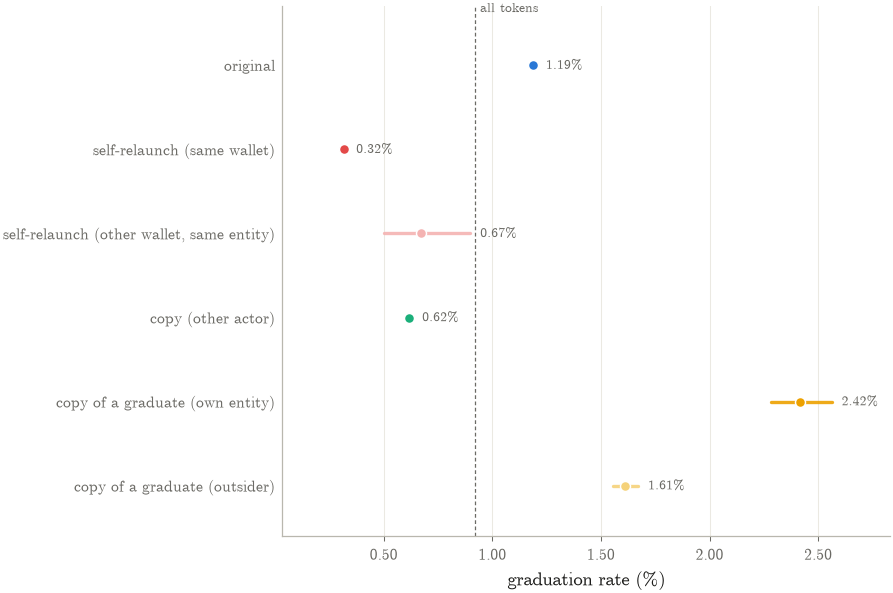

In [21]:
fig, ax = plt.subplots(figsize=FIG_6x4)
forest_by_row(ax, EROLES, erole_t.k, erole_t.n,
              [BLUE, RED, RED_RAMP[0], AQUA, GOLD, "#f5d27a"], ref=tok.grad_fast.mean(), ref_label="all tokens")
ax.set_xlabel(pct_label("graduation rate"))
save(fig, "entity_roles")

### 6.2 Repeat winners: one actor or many?

Images that graduated more than once, through two or more creator wallets. Are those wallets the
same entity?

Repeat-winner images graduated by 2+ creator wallets: 1,977
... all those wallets in ONE entity:   0.8%
... fewer entities than wallets:       1.2%


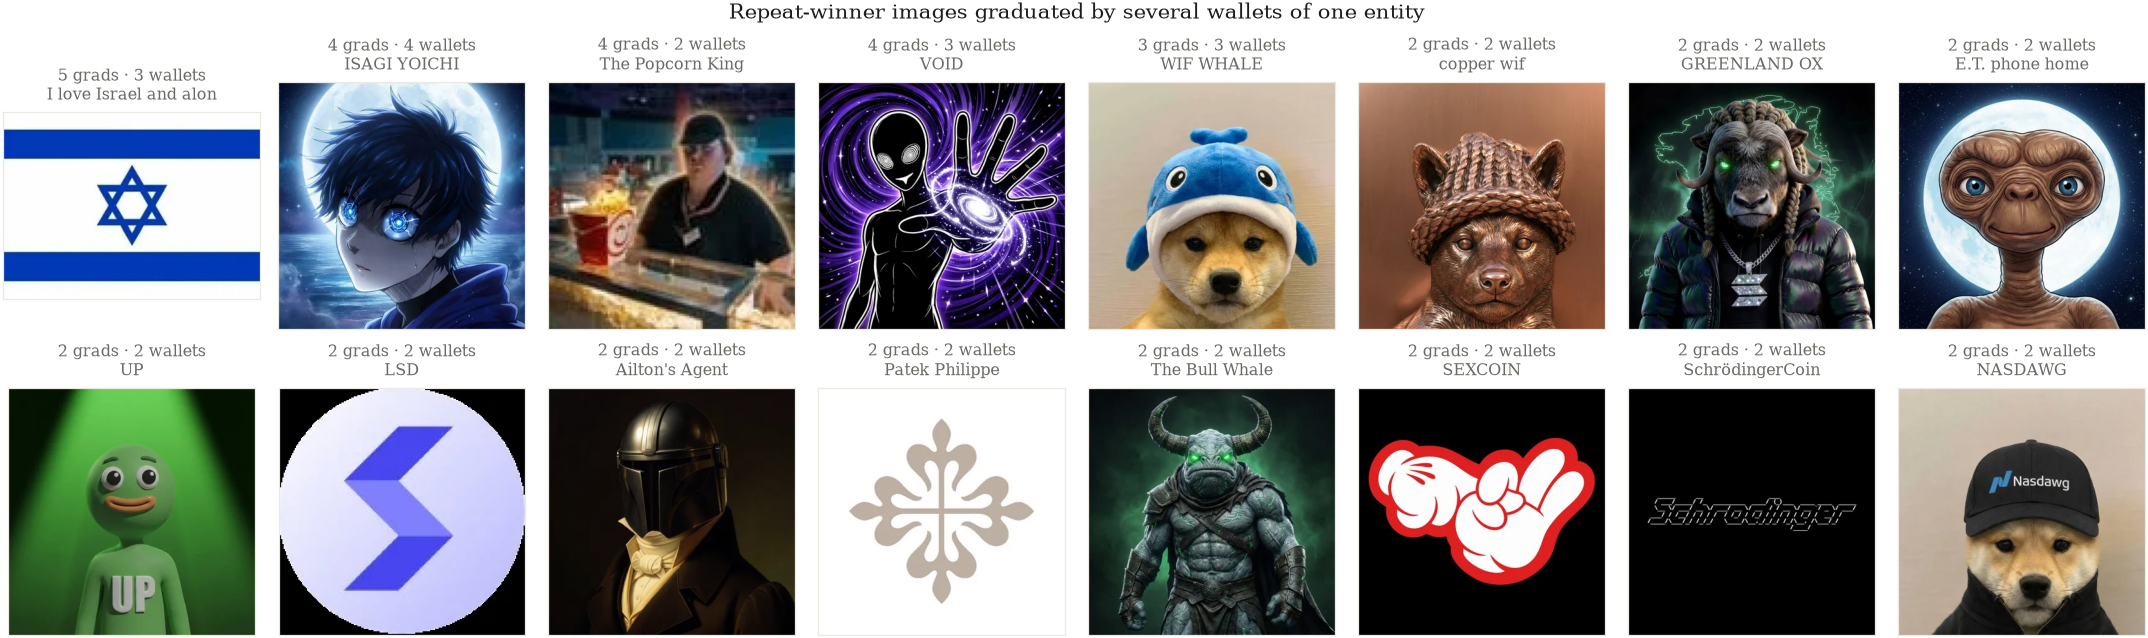

In [22]:
rw = tok[tok.graduated & (tok.image_graduations > 1)]
by_img = rw.groupby("sha256").agg(wallets=("coin_creator", "nunique"), entities=("entity", "nunique"),
                                  graduations=("mint", "size"))
multi_wallet = by_img[by_img.wallets > 1]
print(f"Repeat-winner images graduated by 2+ creator wallets: {len(multi_wallet):,}")
print(f"... all those wallets in ONE entity:   {(multi_wallet.entities == 1).mean():.1%}")
print(f"... fewer entities than wallets:       {(multi_wallet.entities < multi_wallet.wallets).mean():.1%}")

same = multi_wallet[multi_wallet.entities == 1].nlargest(16, "graduations")
same["name"] = pd.Series(same.index).map(names_for(con, same.index)).to_numpy()
if len(same):
    fig = show_grid(con, same.index, [f"{g} grads · {w} wallets\n{n}" for g, w, n in
                                      zip(same.graduations, same.wallets, same.name)],
                    suptitle="Repeat-winner images graduated by several wallets of one entity")
    save(fig, "repeat_winners_one_entity")

### 6.3 Farms by actor instead of by wallet

Graduation rate by how many tokens the **entity** launched, next to the same view by wallet.

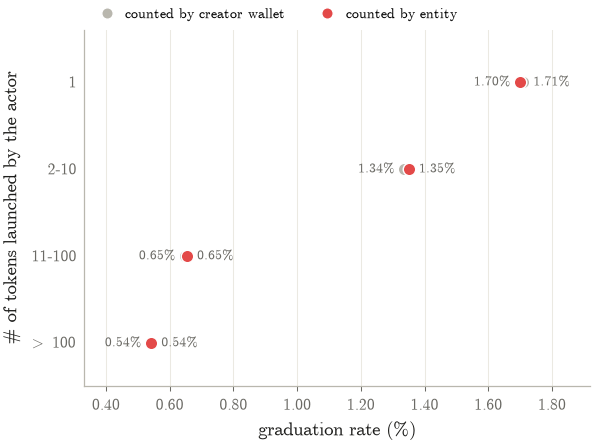

In [23]:
tok["entity_tokens"] = tok.groupby("entity").mint.transform("size")
tok["entity_size"] = pd.cut(tok.entity_tokens, [0, 1, 10, 100, np.inf], labels=SIZES)
by_wallet = rate_table(tok, "creator_size", order=SIZES)
by_entity = rate_table(tok, "entity_size", order=SIZES)
display(pd.concat({"by wallet": by_wallet[["n", "rate"]], "by entity": by_entity[["n", "rate"]]}, axis=1)
        .style.format({("by wallet", "n"): "{:,}", ("by entity", "n"): "{:,}",
                       ("by wallet", "rate"): "{:.2%}", ("by entity", "rate"): "{:.2%}"}))

fig, ax = plt.subplots(figsize=FIG_4x3)
dumbbell(ax, SIZES, by_wallet.rate.to_numpy(), by_entity.rate.to_numpy(), left_label="counted by creator wallet",
         right_label="counted by entity", left_color=MUTED, right_color=RED)
ax.set_xlabel(pct_label("graduation rate"))
ax.set_ylabel(count_label("tokens launched by the actor"))
save(fig, "farms_wallet_vs_entity")

## 7. Export for Gephi

Two graphs at the chosen threshold, in Gephi's spreadsheet CSV format (*File → Import spreadsheet*,
nodes table first, then edges table *appended to the existing workspace*):

- **`entity_graph_*`**: the links that define the entities. Edge `kind` is `coaction` (creator ↔ creator,
  `Weight` = cosine similarity, `shared` = shared bundle wallets) or `cosign` (wallets in the same
  transaction, `Weight` = number of such transactions).
- **`bundle_bipartite_*`**: creator wallets of multi-wallet entities ↔ the wallets buying in their
  creation slots (`Weight` = number of the creator's tokens that wallet bundled). Bundle wallets serving
  creators of more than one entity get `entity = -1`.

Node attributes: `kind`, `entity`, `entity_creators`, `tokens`, `graduations_24h`, `graduation_rate`
and `bundled_launches` (creators), and `creators_served` (bundle wallets). Useful in Gephi: partition by
`entity`, size by `tokens`, ForceAtlas2 layout.

In [24]:
GEPHI_DIR.mkdir(parents=True, exist_ok=True)
entity_creators = creator_entity.value_counts()
creator_stats = tok.groupby("coin_creator").agg(tokens=("mint", "size"), graduations_24h=("grad_fast", "sum"),
                                                bundled_launches=("bundled", "sum"))


def short(wallet):
    return f"{wallet[:4]}...{wallet[-4:]}"


def node_table(ids, entity, kind):
    n = pd.DataFrame({"Id": ids, "Label": [short(w) for w in ids], "kind": kind, "entity": entity})
    n["entity_creators"] = n.entity.map(entity_creators).fillna(0).astype(int)
    n = n.join(creator_stats, on="Id")
    n[["tokens", "graduations_24h", "bundled_launches"]] = (
        n[["tokens", "graduations_24h", "bundled_launches"]].fillna(0).astype(int))
    n["graduation_rate"] = np.where(n.tokens > 0, n.graduations_24h / n.tokens.clip(lower=1), np.nan)
    return n


# 1) entity graph: every link and its endpoints
ends = pd.concat([edges[["source", "entity"]].set_axis(["Id", "entity"], axis=1),
                  edges[["target", "entity"]].set_axis(["Id", "entity"], axis=1)]).drop_duplicates("Id")
eg_nodes = node_table(ends.Id.to_numpy(), ends.entity.to_numpy(),
                      np.where(ends.Id.isin(creator_entity.index), "creator", "wallet"))
eg_edges = edges.rename(columns={"source": "Source", "target": "Target", "weight": "Weight"}).assign(
    Type="Undirected")[["Source", "Target", "Type", "Weight", "kind", "shared", "entity"]]
eg_nodes.to_csv(GEPHI_DIR / "entity_graph_nodes.csv", index=False)
eg_edges.to_csv(GEPHI_DIR / "entity_graph_edges.csv", index=False)

# 2) bipartite creator <-> bundle wallet graph for multi-wallet entities
multi_ids = entity_creators[entity_creators > 1].index
mc = creator_entity[creator_entity.isin(multi_ids)]
bb = (bundle[bundle.coin_creator.isin(mc.index)].groupby(["coin_creator", "trader"]).mint.nunique()
      .rename("Weight").reset_index())
served = bundle.groupby("trader").coin_creator.nunique()
c_nodes = node_table(mc.index.to_numpy(), mc.to_numpy(), "creator")
w_ids = pd.Index(bb.trader.unique()).difference(mc.index)
w_nodes = node_table(w_ids.to_numpy(), wallet_entity.reindex(w_ids).fillna(-1).astype(int).to_numpy(),
                     "bundle wallet")
bp_nodes = pd.concat([c_nodes, w_nodes], ignore_index=True)
bp_nodes["creators_served"] = bp_nodes.Id.map(served).fillna(0).astype(int)
bp_edges = bb.rename(columns={"coin_creator": "Source", "trader": "Target"}).assign(Type="Undirected")[
    ["Source", "Target", "Type", "Weight"]]
bp_nodes.to_csv(GEPHI_DIR / "bundle_bipartite_nodes.csv", index=False)
bp_edges.to_csv(GEPHI_DIR / "bundle_bipartite_edges.csv", index=False)

for f in sorted(GEPHI_DIR.glob("*.csv")):
    print(f"{f.name:32s} {sum(1 for _ in open(f)) - 1:>9,} rows")

bundle_bipartite_edges.csv         198,712 rows
bundle_bipartite_nodes.csv          46,516 rows
entity_graph_edges.csv              54,121 rows
entity_graph_nodes.csv              30,870 rows


## 8. Takeaways

Numbers from the run on 2026-10-19 (5.11M tokens; graduation within 24 h).

1. **A typical launch is engineered.** 95% of tokens have a dev buy in the create transaction,
   39% a bundle (median 2 other wallets, 1.74 SOL in the creation slot), 44% snipers in the next
   3 slots, and in **81%** the creator wallet sells within the first hour.
2. **Bundles go with graduation; early dumping goes against it.** The graduation rate climbs
   steadily with bundle size, from 0.41% with no bundle to **3.77%** with 7+ bundle wallets. Tokens
   whose creator sold within 1 h graduate at 0.61%, against 2.26% when the creator held. Both are
   associations: bundles may be *how* graduations are bought, or how serious launches start.
3. **Farms are cheap, fast and dump.** Wallets with more than 100 tokens (41% of all launches) sell
   within an hour on 86% of their tokens, bundle less than one-off creators (33% vs 65%) and attract
   fewer buyers (median 4 vs 10). Self-relaunches are the cheapest launches (median dev buy
   0.15 SOL, 20% bundled), and the creator comes out ahead on only a third of them.
4. **Copies of a graduate are low-effort but ride the attention.** They bundle less (28%) and put
   in less (median dev buy 0.20 SOL) than originals, yet graduate more. That fits notebook 02:
   the win, not the launch setup, drives them.
5. **Repeat-winner graduations are thin.** Graduations of images that had graduated before needed a
   median of **20** distinct buyers, against **235** for one-time winners. **24%** of them had at
   most 5 buyers, so a handful of wallets supplied the ~85 SOL a curve needs. This points to
   manufactured graduations rather than crowd demand.
6. **Entities (τ = 0.7): real, but mostly small.** Co-action + co-signing links give 6,487
   multi-wallet entities covering 22k creator wallets (73.7k at τ = 0.5, 3.2k at τ = 0.9). The links
   are validated by data they never saw: wallets of the same entity share images **406×** more than
   under shuffled entities.
7. **Two kinds of farm.** The biggest farms run from **single wallets**: the top 0.1% of creator
   wallets launch 27.9% of all tokens, the top 25 between 6k and 12k tokens each, nearly every day
   for months (farm cadence figure). The multi-wallet entities are a different strategy: **61.7%**
   of them launch exactly **one token per wallet** and share a small pool of bundle wallets (entity
   network figure), i.e. deliberate wallet rotation. Because these rotating farms do not reuse their
   images, they barely change the image-based findings. Only 0.5% of "copies by another creator" and
   0.8% of multi-wallet repeat winners turn out to be one entity, and launch concentration is the
   same counted by wallet or by entity (Gini 0.72). Relaunching your *own* winner graduates more
   (2.42%) than outsiders copying it (1.61%).
8. **Bundling helps most for small serial creators, and farms launch around the clock.** With 7+
   bundle wallets, creators of 2–10 tokens graduate at 6.8%, one-off creators at 3.3% and 100+ token
   farms at 2.6%. Without a bundle, every group is below 1%. Farms follow a flatter daily rhythm
   than one-off creators (busiest hour 1.9× the quietest vs 2.4×).

The coordination graphs are exported for Gephi in `reports/gephi/03_trades_coordination_entities/`
(section 7).

**Limitations.** Entity links exist only for creators whose launches had bundles (879k creators),
and they cannot see wallets that share nothing but a funding source. The datalake has no SOL
transfers, so the standard *funding-source* heuristic (wallets first funded by the same address,
widely used for Sybil detection) is not available. Points 6–7 are therefore a **lower bound** on
multi-wallet coordination. "Creator net" counts only the creator wallet on the bonding curve:
post-graduation trading (PumpSwap) and sells through other wallets are not included, which is why
graduates show a negative mean.

**Next steps.** (a) Crawl each creator wallet's first incoming SOL transfer (one RPC call per wallet)
and add funding links: the most direct test of whether repeat winners' "different creators" are one
actor. (b) Keep per-wallet sells to measure what bundle wallets extract. (c) Pre-graduation buyer
concentration (top-5 wallets' share of the ~85 SOL) for every graduation.